# 03 · Signatures — embryonic-development module scores & Gate 2

The three embryonic modules (**Gast** gastrulation, **pSom** posterior somitogenesis, **Crest** neural
crest) were scored in 02 against the shared **union** control pool and graph-smoothed. Here we test
**Gate 2** — the module geography on the manifold — and render the per-module signature UMAPs
(deliverable shows **raw** per-cell scores so 10x dropout stays visible; smoothed scores are used only
for the quantitative geography read). Deliverable: `{Gast,pSom,Crest}_signature.pdf` + colorbars,
`signatures.h5ad`.

In [1]:
import os, sys, glob, warnings
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import scanpy as sc, matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load the rooted manifold (signatures scored + smoothed in 02)

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'manifold.h5ad'))
modules = {'Gast':'Gastrulation', 'pSom':'Somitogenesis', 'Crest':'Neural Crest'}
print('cells:', adata.shape[0], '| scores present:', [m for m in modules if m in adata.obs])
print('global module means (defines the Linear split):',
      {m: round(float(adata.obs[m].mean()),3) for m in modules})

cells: 18491 | scores present: ['Gast', 'pSom', 'Crest']
global module means (defines the Linear split): {'Gast': -0.017, 'pSom': 0.005, 'Crest': 0.007}


### Gate 2 — module geography on the manifold
Quantitative test of the **non-branching** signature for this dataset: (i) whether Gast and pSom
resolve into two competing arms or collapse onto one axis; (ii) whether Crest is an inverse/terminal
gradient anti-correlated with the early modules; (iii) the pseudotime ordering. Here Gast and pSom do
**not** split into opposing arms — Gast declines and pSom rises along a single axis, while Crest is
strongly anti-correlated with Gast (raw per-cell r ~ -0.55, not a smoothing artifact) and peaks toward
the terminus. This is the **non-branching case** (single developmental axis, Crest inverse/terminal
gradient) -> **Gate 2 = GO**, and with no bifurcation **Gate 3 = NA**.

In [4]:
print('RAW per-cell pairwise correlations (dropout-robust check):')
for a,b in [('Gast','pSom'),('Crest','Gast'),('Crest','pSom')]:
    print(f'  {a} vs {b}: r = {np.corrcoef(adata.obs[a],adata.obs[b])[0,1]:+.3f}')
print('SMOOTHED spatial correlations (geography):')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    print(f'  {a} vs {b}: r = {np.corrcoef(adata.obs[a],adata.obs[b])[0,1]:+.3f}')
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('gradient along pseudotime (Spearman rho on smoothed):')
for s in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,_ = spearmanr(t, adata.obs[s]); print(f'  {s}: rho = {rho:+.3f}')
hi = adata.obs['Crest_sm'] >= adata.obs['Crest_sm'].quantile(0.9)
print(f'Neural-crest-high decile mean pseudotime = {tn[hi.values].mean():.2f} (terminal if high)')
print('Gate 2: single Gast->pSom/Crest axis, Crest inverse-terminal gradient -> GO (non-branching)')
print('Gate 3: no bifurcation -> NA')

RAW per-cell pairwise correlations (dropout-robust check):
  Gast vs pSom: r = +0.050
  Crest vs Gast: r = -0.553
  Crest vs pSom: r = -0.546
SMOOTHED spatial correlations (geography):
  Gast_sm vs pSom_sm: r = -0.204
  Crest_sm vs Gast_sm: r = -0.737
  Crest_sm vs pSom_sm: r = -0.027
gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho = -0.624
  pSom_sm: rho = +0.490
  Crest_sm: rho = +0.079
Neural-crest-high decile mean pseudotime = 0.73 (terminal if high)
Gate 2: single Gast->pSom/Crest axis, Crest inverse-terminal gradient -> GO (non-branching)
Gate 3: no bifurcation -> NA


### Module maps (house linear layout, pseudotime left -> right)
Quick composite of the three raw module scores on the house orientation for inspection; the individual
deliverable panels + colorbars are written next.

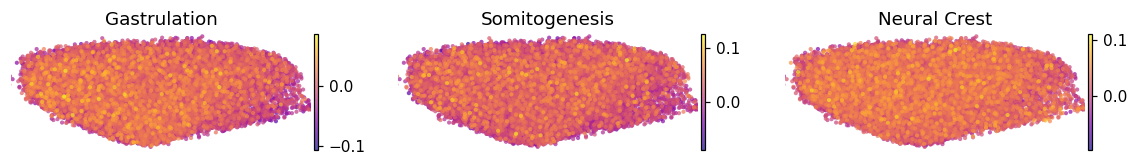

In [5]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
fig, axes = plt.subplots(1, 3, figsize=(10.5,1.6))
for ax,(m,title) in zip(axes, modules.items()):
    sc.pl.umap(plot, color=m, cmap='plasma', alpha=.7, size=30, colorbar_loc='right',
               frameon=False, show=False, ax=ax, title=title)
    ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
fig.tight_layout()

### Per-module signature figures + colorbars (deliverable)
House style: `figsize=(3.5,1.5)`, pseudotime left->right (`X_umap_lin`), `size=30`, plasma, **raw** (not
smoothed) score per cell so 10x dropout is visible.

saved Gast_signature.pdf + colorbar
saved pSom_signature.pdf + colorbar
saved Crest_signature.pdf + colorbar


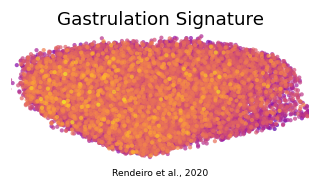

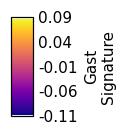

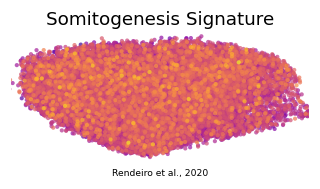

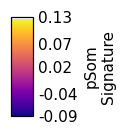

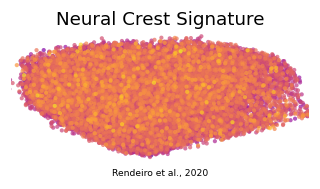

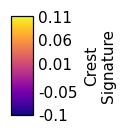

In [6]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
titles = {'Gast':'Gastrulation Signature','pSom':'Somitogenesis Signature','Crest':'Neural Crest Signature'}
for m in ['Gast','pSom','Crest']:
    fig, ax = plt.subplots(figsize=(3.5,1.5))
    sc.pl.umap(plot, color=m, cmap='plasma', alpha=.7, size=30, colorbar_loc=None,
               frameon=False, show=False, ax=ax, title=titles[m])
    ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
    ax.text(.5,-.12,'Rendeiro et al., 2020', ha='center', transform=ax.transAxes, size=6)
    fig.savefig(os.path.join(pth_fig, f'{m}_signature.pdf'), bbox_inches='tight')
    lo, hi = float(adata.obs[m].min()), float(adata.obs[m].max())
    ticks = np.round(np.linspace(lo, hi, 5), 2)
    fcb = plt.figure(figsize=(.66,1)); cax = fcb.add_axes([.35,.05,.3,.9])
    cb = plt.colorbar(ax.collections[0], cax=cax); cb.ax.tick_params(which='both', size=0)
    cb.set_label(f'{m}\nSignature'); cb.set_ticks(ticks, labels=ticks); cb.solids.set_alpha(1)
    fcb.savefig(os.path.join(pth_cb, f'{m}_colorbar.pdf'), bbox_inches='tight')
    print('saved', f'{m}_signature.pdf', '+ colorbar')

### Save signatures data

In [7]:
adata.write(os.path.join(pth_out, 'signatures.h5ad'))
print('saved signatures.h5ad', adata.shape)

saved signatures.h5ad (18491, 14889)
